# Day 2: Explore the data sources
**Question:** How do Delhi's PM2.5 levels vary by season, time of day and weather, and can I forecast tomorrow's AQI?

This notebook pulls a week of air quality and weather data from Open-Meteo, inspects it, merges it and plots it.

In [17]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

LAT, LON = 28.6139, 77.2090  # Delhi
TZ = "Asia/Kolkata"

AQ_URL = "https://air-quality-api.open-meteo.com/v1/air-quality"
WX_URL = "https://api.open-meteo.com/v1/forecast"

def get_json(url, params):
    r = requests.get(url, params=params, timeout=30)
    print(r.status_code, r.url)
    if not r.ok:
        print(r.text)  # the API usually explains what is wrong
        r.raise_for_status()
    return r.json()

## 1. Pull a sample from both APIs

In [3]:
aq = get_json(AQ_URL, {
    "latitude": LAT, "longitude": LON,
    "hourly": "pm2_5,pm10,us_aqi",
    "past_days": 7, "forecast_days": 1,
    "timezone": TZ,
})

wx = get_json(WX_URL, {
    "latitude": LAT, "longitude": LON,
    "hourly": "temperature_2m,relative_humidity_2m,wind_speed_10m",
    "past_days": 7, "forecast_days": 1,
    "timezone": TZ,
})

aq_df = pd.DataFrame(aq["hourly"])
wx_df = pd.DataFrame(wx["hourly"])
print(aq_df.shape, wx_df.shape)

200 https://air-quality-api.open-meteo.com/v1/air-quality?latitude=28.6139&longitude=77.209&hourly=pm2_5%2Cpm10%2Cus_aqi&past_days=7&forecast_days=1&timezone=Asia%2FKolkata
200 https://api.open-meteo.com/v1/forecast?latitude=28.6139&longitude=77.209&hourly=temperature_2m%2Crelative_humidity_2m%2Cwind_speed_10m&past_days=7&forecast_days=1&timezone=Asia%2FKolkata
(192, 4) (192, 4)


## 2. Inspect each dataset

In [4]:
print("UNITS (air quality):", aq.get("hourly_units"))
aq_df.head()

UNITS (air quality): {'time': 'iso8601', 'pm2_5': 'μg/m³', 'pm10': 'μg/m³', 'us_aqi': 'USAQI'}


,time,pm2_5,pm10,us_aqi
0,2026-11-04T00:00,153.7,319.4,194
1,2026-11-04T01:00,152.3,294.3,196
2,2026-11-04T02:00,149.5,267.3,197
3,2026-11-04T03:00,146.2,243.1,198
4,2026-11-04T04:00,143.4,224.4,199


In [5]:
aq_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   time    192 non-null    str    
 1   pm2_5   192 non-null    float64
 2   pm10    192 non-null    float64
 3   us_aqi  192 non-null    int64  
dtypes: float64(2), int64(1), str(1)
memory usage: 6.1 KB


In [6]:
aq_df.describe()

,pm2_5,pm10,us_aqi
count,192.000000,192.000000,192.000000
mean,121.015625,181.519271,198.817708
std,36.481249,54.461595,18.074398
min,48.700000,78.200000,172.000000
25%,91.300000,143.325000,179.000000
50%,116.400000,178.550000,204.000000
75%,152.300000,215.950000,211.000000
max,201.200000,319.400000,230.000000


In [7]:
aq_df.isna().sum()

time      0
pm2_5     0
pm10      0
us_aqi    0
dtype: int64

In [8]:
print("UNITS (weather):", wx.get("hourly_units"))
wx_df.head()

UNITS (weather): {'time': 'iso8601', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'wind_speed_10m': 'km/h'}


,time,temperature_2m,relative_humidity_2m,wind_speed_10m
0,2026-11-04T00:00,20.4,77,5.4
1,2026-11-04T01:00,20.1,78,5.1
2,2026-11-04T02:00,20.1,77,3.8
3,2026-11-04T03:00,19.6,78,4.0
4,2026-11-04T04:00,18.8,82,4.4


In [9]:
wx_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   time                  192 non-null    str    
 1   temperature_2m        192 non-null    float64
 2   relative_humidity_2m  192 non-null    int64  
 3   wind_speed_10m        192 non-null    float64
dtypes: float64(2), int64(1), str(1)
memory usage: 6.1 KB


In [10]:
wx_df.describe()

,temperature_2m,relative_humidity_2m,wind_speed_10m
count,192.000000,192.000000,192.000000
mean,23.083854,67.546875,4.794792
std,3.259380,11.676167,1.722160
min,17.500000,39.000000,0.600000
25%,20.200000,60.000000,3.800000
50%,22.600000,68.000000,4.950000
75%,25.900000,77.250000,5.900000
max,28.600000,86.000000,9.500000


In [11]:
wx_df.isna().sum()

time                    0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
dtype: int64

## 3. Check timestamps
The API returns forecast hours for the rest of today. These are predictions, not real readings, so I will remove them.

In [12]:
aq_df["time"] = pd.to_datetime(aq_df["time"])
wx_df["time"] = pd.to_datetime(wx_df["time"])

now_local = pd.Timestamp.now(tz=TZ).tz_localize(None)
print("Now (Delhi):", now_local)
print("Air quality range:", aq_df["time"].min(), "->", aq_df["time"].max())
print("Weather range:    ", wx_df["time"].min(), "->", wx_df["time"].max())
print("Duplicate timestamps (aq, wx):", aq_df["time"].duplicated().sum(), wx_df["time"].duplicated().sum())

# Keep only past hours so forecasts are not stored as real readings
aq_df = aq_df[aq_df["time"] <= now_local]
wx_df = wx_df[wx_df["time"] <= now_local]
print(aq_df.shape, wx_df.shape)

Now (Delhi): 2026-11-11 13:27:27.338286
Air quality range: 2026-11-04 00:00:00 -> 2026-11-11 23:00:00
Weather range:     2026-11-04 00:00:00 -> 2026-11-11 23:00:00
Duplicate timestamps (aq, wx): 0 0
(182, 4) (182, 4)


## 4. Merge the two datasets on time

In [13]:
merged = aq_df.merge(wx_df, on="time", how="inner")
print("aq rows:", len(aq_df), "| wx rows:", len(wx_df), "| merged rows:", len(merged))

# Rows that did not match in either direction
outer = aq_df.merge(wx_df, on="time", how="outer", indicator=True)
print(outer["_merge"].value_counts())

merged.head()

aq rows: 182 | wx rows: 182 | merged rows: 182
_merge
both          182
left_only       0
right_only      0
Name: count, dtype: int64


,time,pm2_5,pm10,us_aqi,temperature_2m,relative_humidity_2m,wind_speed_10m
0,2026-11-04 00:00:00,153.7,319.4,194,20.4,77,5.4
1,2026-11-04 01:00:00,152.3,294.3,196,20.1,78,5.1
2,2026-11-04 02:00:00,149.5,267.3,197,20.1,77,3.8
3,2026-11-04 03:00:00,146.2,243.1,198,19.6,78,4.0
4,2026-11-04 04:00:00,143.4,224.4,199,18.8,82,4.4


In [14]:
merged.isna().sum()

time                    0
pm2_5                   0
pm10                    0
us_aqi                  0
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
dtype: int64

## 5. Quick plots
If you get `ModuleNotFoundError: matplotlib`, run `%pip install matplotlib` in a cell, restart the kernel, and try again.

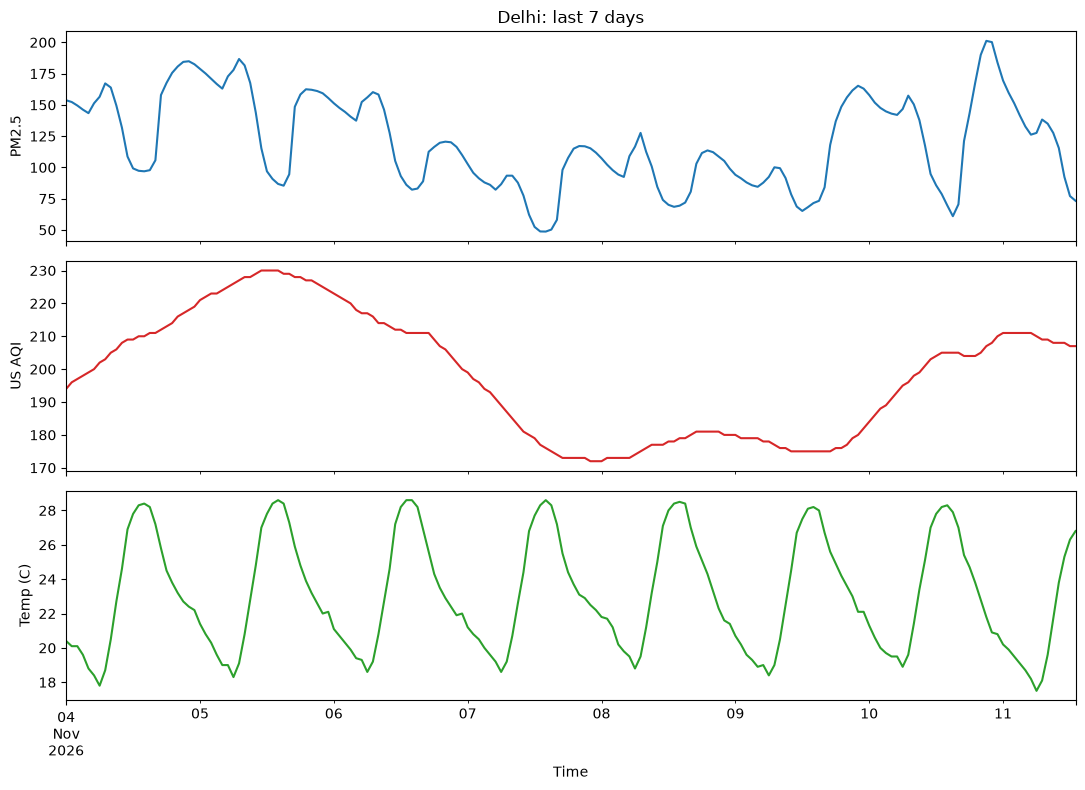

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

merged.plot(x="time", y="pm2_5", ax=axes[0], legend=False)
axes[0].set_ylabel("PM2.5")
axes[0].set_title("Delhi: last 7 days")

merged.plot(x="time", y="us_aqi", ax=axes[1], legend=False, color="tab:red")
axes[1].set_ylabel("US AQI")

merged.plot(x="time", y="temperature_2m", ax=axes[2], legend=False, color="tab:green")
axes[2].set_ylabel("Temp (C)")
axes[2].set_xlabel("Time")

plt.tight_layout()
plt.show()

In [16]:
# Does PM2.5 relate to weather? A first quick look
merged[["pm2_5", "pm10", "us_aqi", "temperature_2m", "relative_humidity_2m", "wind_speed_10m"]].corr().round(2)

,pm2_5,pm10,us_aqi,temperature_2m,relative_humidity_2m,wind_speed_10m
pm2_5,1.00,0.71,0.51,-0.54,0.50,-0.15
pm10,0.71,1.00,0.35,-0.47,0.41,0.02
us_aqi,0.51,0.35,1.00,-0.02,0.02,0.25
temperature_2m,-0.54,-0.47,-0.02,1.00,-0.94,0.26
relative_humidity_2m,0.50,0.41,0.02,-0.94,1.00,-0.27
wind_speed_10m,-0.15,0.02,0.25,0.26,-0.27,1.00


## 6. My findings (fill in, then copy into `docs/data-notes.md`)
- **Sources and columns: the two URLs from the first code block
      AQ_URL = "https://air-quality-api.open-meteo.com/v1/air-quality" for Air Quality API
      WX_URL = "https://api.open-meteo.com/v1/forecast" for  Weather API
      Columns are the output of these two functions aq_df.head() and wx_df.head() **
- **Units: PM2.5 in µg/m³, temperature in °C, wind speed in km/h
      UNITS (air quality): {'time': 'iso8601', 'pm2_5': 'μg/m³', 'pm10': 'μg/m³', 'us_aqi': 'USAQI'}
      UNITS (weather): {'time': 'iso8601', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'wind_speed_10m': 'km/h'} **
- **Timezone handling: request included timezone=Asia/Kolkata, so timestamps are in Indian local time **
- **Missing values / gaps: non null values in the last 7 days for both air quality and weather
      aq rows: 182 | wx rows: 182 | merged rows: 182
      _merge
      both          182
      left_only       0
      right_only      0
      Name: count, dtype: int64 **
- **Odd values or spikes: check the output of .describe() function for both air quality and weather **
- **Forecast vs real readings: API includes future hours for today; filtered out
      Now (Delhi): 2026-11-11 13:27:27.338286
      Air quality range: 2026-11-04 00:00:00 -> 2026-11-11 23:00:00
      Weather range:     2026-11-04 00:00:00 -> 2026-11-11 23:00:00
      Duplicate timestamps (aq, wx): 0 0
      (182, 4) (182, 4) **
- **Cleaning decisions for Day 3: need to perform the below steps for day 3
       Drop rows after the current time
       Parse time as datetime
       Inner-merge on time
       Decide what to do with missing values (leave as null, or fill)
       Flag impossible values (like negative PM2.5) **

In [1]:
import sys
print(sys.executable)

C:\Users\dell\delhi-air-quality-pipeline-and-dashboard\.venv\Scripts\python.exe
